# 02 · Revenue forecasting (v1)

> This is **v1**. Its results are kept in `reports/revenue_model_comparison_v1.csv` and `models/revenue_model_v1.*`; the improved v2 is notebook 03.

Goal: forecast **daily net revenue** for the admin dashboard, with an 80% range, and pick the most accurate model.

- **Data:** `load_daily_revenue()` from `ml-service/forecasting/data.py`, the same revenue as the dashboard and notebook 01
  (paid orders only, dated by `paid_at` in Malaysia time, net of refunds; days without sales = RM 0).
- **Calendar:** Malaysian events from `forecasting/calendar.py` (payday, double days, Black Friday, Hari Raya, CNY, Deepavali, school reopening, month-end, December).
  Holiday dates are provisional and must be checked against official sources.
- **Models:** `forecasting/models.py`. All four share one interface: `fit(history)` and `predict(dates)` → forecast + 80% interval.
- **Test design:** the last **91 days** (13 weeks). *Rolling origin*: every 7 days, each model is trained on all data before that day
  and forecasts the next 7 days, just as it would be used each week in the shop. No model ever sees the week it is forecasting.

In [1]:
import json
import logging
import sys
import warnings
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

logging.getLogger("prophet.plot").setLevel(logging.ERROR)  # plotly isn't needed
logging.getLogger("cmdstanpy").setLevel(logging.ERROR)
warnings.filterwarnings("ignore")

ML_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ML_DIR))
from forecasting.calendar import FEATURES, calendar_features  # noqa: E402
from forecasting.data import load_daily_revenue  # noqa: E402
from forecasting.evaluation import metrics, rolling_origin_backtest  # noqa: E402
from forecasting.models import ProphetModel, Sarima, SeasonalNaive, XGBoostModel  # noqa: E402

FIG_DIR = ML_DIR / "reports" / "figures"
REPORT_DIR = ML_DIR / "reports"
MODEL_DIR = ML_DIR / "models"
for folder in (FIG_DIR, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)

TEST_DAYS, STEP = 91, 7
COLORS = {"Seasonal naive": "#78716c", "SARIMA": "#1d4ed8", "Prophet": "#d97706", "XGBoost": "#047857"}

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.titlesize": 13, "axes.titleweight": "bold"})
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")


def save(fig, name):
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    print("saved", name)


def rm_axis(ax):
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"RM {v:,.0f}"))

## 1. Data and calendar

In [2]:
y = load_daily_revenue()
test_start = y.index[-TEST_DAYS]
print(f"{len(y)} days: {y.index.min():%d %b %Y} to {y.index.max():%d %b %Y} · total RM {y.sum():,.0f} · days with no sales: {int((y == 0).sum())}")
print(f"Training before {test_start:%d %b %Y} ({(y.index < test_start).sum()} days) · test {test_start:%d %b %Y} to {y.index.max():%d %b %Y} ({TEST_DAYS} days, {TEST_DAYS // STEP} weekly folds)")

cal = calendar_features(y.index)
effect = pd.DataFrame({
    "days flagged": cal.sum(),
    "avg revenue on flagged days (RM)": [y[cal[c] == 1].mean() for c in FEATURES],
    "avg revenue other days (RM)": [y[cal[c] == 0].mean() for c in FEATURES],
})
effect["difference"] = effect["avg revenue on flagged days (RM)"] / effect["avg revenue other days (RM)"] - 1
effect.style.format({"days flagged": "{:,.0f}", "avg revenue on flagged days (RM)": "RM {:,.0f}", "avg revenue other days (RM)": "RM {:,.0f}", "difference": "{:+.0%}"})

737 days: 01 Nov 2024 to 07 Nov 2026 · total RM 584,575 · days with no sales: 56
Training before 09 Aug 2026 (646 days) · test 09 Aug 2026 to 07 Nov 2026 (91 days, 13 weekly folds)


,days flagged,avg revenue on flagged days (RM),avg revenue other days (RM),difference
payday,204,RM 836,RM 777,+8%
double_day,8,"RM 1,247",RM 788,+58%
double_day_adjacent,16,RM 749,RM 794,-6%
black_friday,8,RM 530,RM 796,-33%
pre_raya,42,"RM 1,084",RM 776,+40%
raya_closure,8,RM 614,RM 795,-23%
chinese_new_year,4,RM 802,RM 793,+1%
deepavali,1,RM 355,RM 794,-55%
back_to_school,28,RM 845,RM 791,+7%
month_end,24,RM 745,RM 795,-6%


**Finding:** 737 days, RM 584,575 in total. The model trains on 646 days and is tested on the last 91 (9 Aug – 7 Nov 2026). The calendar flags carry real signal: double days average +58% and the 21 days before Hari Raya +40%, while payday (+8%) and back-to-school (+7%) are small lifts. The Raya closure days are −23%. Black Friday is −33%, so it isn't a sales event for this shop. CNY has no effect, and Deepavali occurs only once in the data, too rarely to learn. The test window contains 9.9 and 10.10 but no 11.11, 12.12 or Raya, so the backtest mostly measures normal weeks.

## 2. The four models, in simple words

| Model | How it forecasts | Why it's here |
|---|---|---|
| **Seasonal naive** | Tomorrow = the same weekday last week. | The **baseline**: a model is only useful if it beats this. |
| **SARIMA** | A statistical model of how today's revenue depends on recent days and the same weekday in past weeks (weekly season s = 7), plus the calendar flags as extra inputs. Orders chosen by AIC. | The classic time-series method; gives proper statistical intervals. |
| **Prophet** | Splits revenue into a smooth trend, a weekly pattern and a yearly pattern, and adds an effect for each Malaysian event (double days, Black Friday, Hari Raya, CNY, Deepavali) plus payday / pre-Raya / back-to-school / month-end. | Made for business data with holidays; easy to explain. |
| **XGBoost** | Many small decision trees learn revenue from the date (weekday, day of month, month), the calendar flags and past revenue (7, 14 and 28 days ago, and 7/28-day averages ending 7 days ago). Trained three times: for the 10%, 50% and 90% point. | Machine learning that can combine many signals; the lags are always at least 7 days old, so a weekly forecast never peeks at the future. |

All four return a forecast and an **80% interval** (the range the real value should fall in 8 days out of 10).

## 3. SARIMA: choosing the orders
A small grid (p, q ∈ {0, 1, 2}, d ∈ {0, 1}, seasonal P, Q ∈ {0, 1} with s = 7), fitted on the training data only (before the test period).
The lowest **AIC** (fit quality with a penalty for extra parameters) wins. d = 0 uses a constant + linear trend; d = 1 a drift.

In [3]:
grid = Sarima.select_order(y[y.index < test_start])
best_order, best_seasonal = grid.loc[0, "order"], grid.loc[0, "seasonal_order"]
print(f"{len(grid)} combinations · best: SARIMA{best_order}x{best_seasonal}, AIC {grid.loc[0, 'aic']:,.1f}")
grid.head(8)

72 combinations · best: SARIMA(0, 0, 0)x(0, 0, 0, 7), AIC 9,996.3


,order,seasonal_order,aic
0,"(0, 0, 0)","(0, 0, 0, 7)","9,996.30"
1,"(1, 1, 2)","(0, 0, 0, 7)","10,000.28"
2,"(1, 0, 0)","(0, 0, 0, 7)","10,001.08"
3,"(0, 0, 0)","(0, 0, 1, 7)","10,001.56"
4,"(0, 0, 0)","(1, 0, 0, 7)","10,002.58"
5,"(1, 0, 1)","(0, 0, 0, 7)","10,003.39"
6,"(2, 1, 2)","(0, 0, 1, 7)","10,004.53"
7,"(2, 0, 0)","(1, 0, 0, 7)","10,004.75"


**Finding:** The AIC grid picks **SARIMA(0,0,0)×(0,0,0,7)**, so no AR, MA or seasonal term beats a plain regression on a linear trend plus the calendar flags; the next best order is 4 AIC points worse. That matches notebook 01: autocorrelation is weak (0.19 at lag 1), and the day-to-day movement is mostly noise. In practice this "SARIMA" is a trend + calendar regression, and it has no weekday input (the weekday effect is small anyway).

## 4. Rolling-origin backtest (last 91 days)
Each model is refitted 13 times (once per week) and forecasts the following 7 days.

In [4]:
models = [SeasonalNaive(), Sarima(best_order, best_seasonal), ProphetModel(), XGBoostModel()]
backtest = rolling_origin_backtest(models, y, test_days=TEST_DAYS, step=STEP)
backtest.head()

Seasonal naive         13 folds in 0 s


SARIMA                 13 folds in 14 s


Prophet                13 folds in 4 s


XGBoost                13 folds in 7 s


,model,origin,date,actual,yhat,lower,upper
0,Seasonal naive,2026-08-09,2026-08-09,"1,105.00",575.00,0.00,"1,485.00"
1,Seasonal naive,2026-08-09,2026-08-10,235.00,"1,185.00",245.00,"2,095.00"
2,Seasonal naive,2026-08-09,2026-08-11,540.00,825.00,0.00,"1,735.00"
3,Seasonal naive,2026-08-09,2026-08-12,765.00,110.00,0.00,"1,020.00"
4,Seasonal naive,2026-08-09,2026-08-13,"2,895.00","1,640.00",700.00,"2,550.00"


### Results
- **MAE**: average error per day in RM. **RMSE**: like MAE but punishes big misses more.
- **WAPE**: total error ÷ total revenue, in %. **Weekly total error**: how far off each 7-day total is (what the admin sees on the dashboard).
- **Weekly total bias**: positive = the model over-forecasts on average. **80% interval coverage**: should be close to 80%.

In [5]:
results = metrics(backtest)
results.round(2).to_csv(REPORT_DIR / "revenue_model_comparison_v1.csv", index=False)
print("saved reports/revenue_model_comparison_v1.csv")
baseline = results.set_index("model").loc["Seasonal naive", "MAE (RM)"]
results["MAE vs baseline"] = results["MAE (RM)"] / baseline - 1
results.style.format({"MAE (RM)": "RM {:,.0f}", "RMSE (RM)": "RM {:,.0f}", "WAPE (%)": "{:.1f}%", "weekly total error (%)": "{:.1f}%",
                      "weekly total bias (%)": "{:+.1f}%", "80% interval coverage (%)": "{:.0f}%", "MAE vs baseline": "{:+.0%}"}).hide(axis="index")

saved reports/revenue_model_comparison_v1.csv


model,MAE (RM),RMSE (RM),WAPE (%),weekly total error (%),weekly total bias (%),80% interval coverage (%),MAE vs baseline
XGBoost,RM 587,RM 740,57.8%,27.0%,-3.6%,65%,-33%
SARIMA,RM 643,RM 763,63.3%,36.4%,+24.3%,64%,-26%
Prophet,RM 647,RM 774,63.7%,40.9%,+26.1%,58%,-26%
Seasonal naive,RM 875,"RM 1,078",86.1%,35.2%,+11.3%,64%,+0%


**Finding:** **XGBoost wins**: MAE RM 587 a day, 33% better than the seasonal-naive baseline (RM 875), with a 27% error on weekly totals (baseline 35%) and almost no bias (−4%). SARIMA (RM 643) and Prophet (RM 647) beat the baseline day by day, but they over-forecast weekly totals by about 25% and are **worse than the baseline on weekly totals** (36% and 41% vs 35%). Daily WAPE is 58% or higher for every model, so single days can't be forecast precisely. All 80% intervals are too narrow: they caught the real value only 58–65% of the time.

### Actual vs forecast over the test period

saved 04_backtest_actual_vs_forecast.png


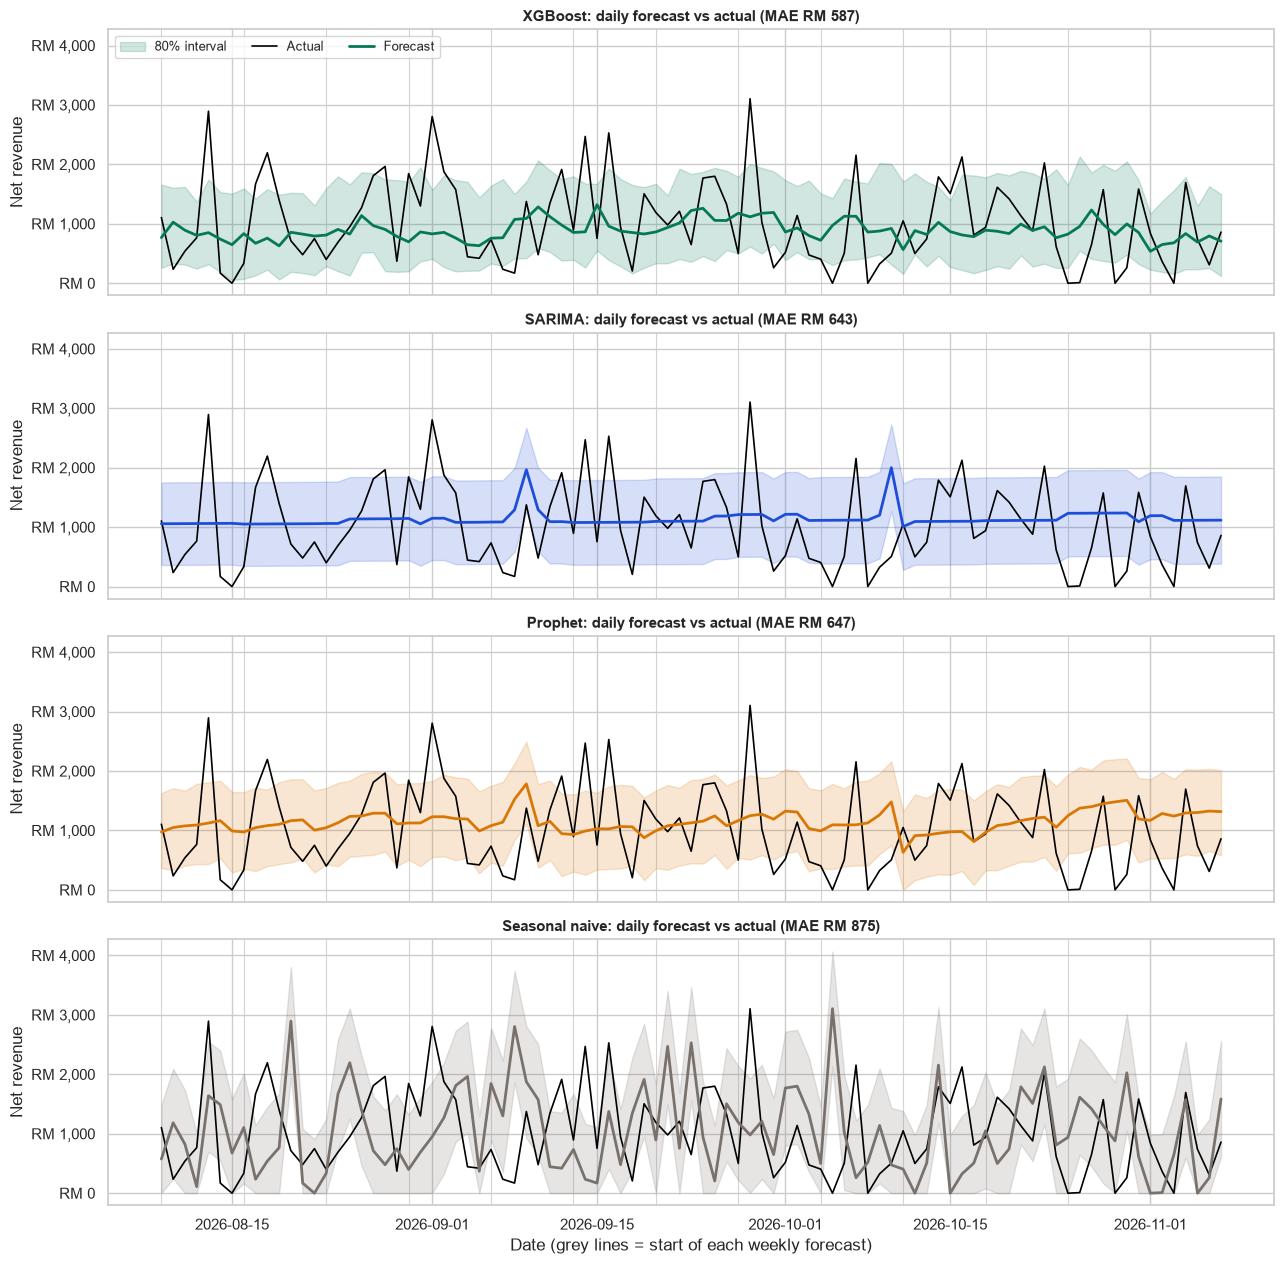

In [6]:
names = list(results["model"])
fig, axes = plt.subplots(len(names), 1, figsize=(13, 3.2 * len(names)), sharex=True, sharey=True)
for ax, name in zip(axes, names):
    part = backtest[backtest["model"] == name].set_index("date")
    ax.fill_between(part.index, part["lower"], part["upper"], color=COLORS[name], alpha=0.18, label="80% interval")
    ax.plot(part.index, part["actual"], color="black", lw=1.2, label="Actual")
    ax.plot(part.index, part["yhat"], color=COLORS[name], lw=2, label="Forecast")
    for origin in part["origin"].unique():
        ax.axvline(origin, color="#d6d3d1", lw=0.8, zorder=0)
    mae = results.set_index("model").loc[name, "MAE (RM)"]
    ax.set_title(f"{name}: daily forecast vs actual (MAE RM {mae:,.0f})", fontsize=11)
    ax.set_ylabel("Net revenue")
    rm_axis(ax)
axes[0].legend(loc="upper left", ncol=3, fontsize=9)
axes[-1].set_xlabel("Date (grey lines = start of each weekly forecast)")
fig.tight_layout()
save(fig, "04_backtest_actual_vs_forecast.png")
plt.show()

saved 04_weekly_totals.png


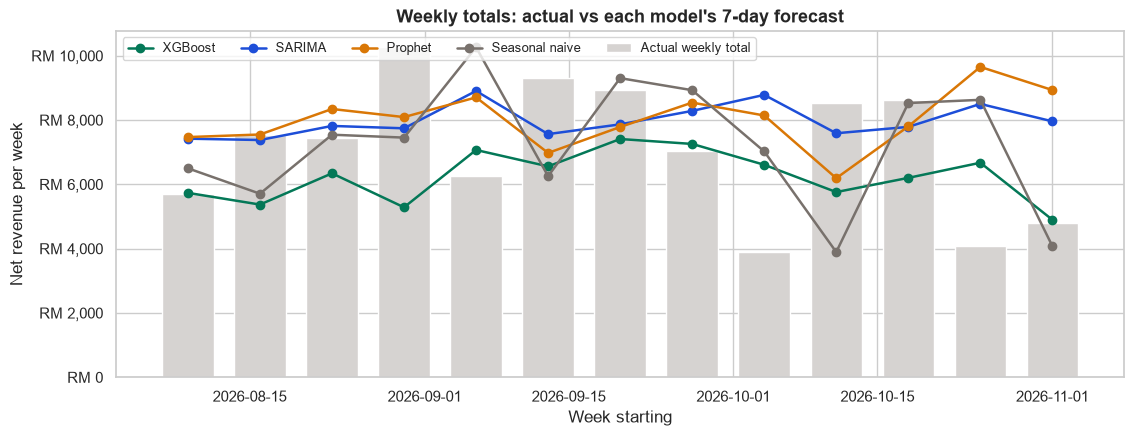

In [7]:
weekly = backtest.groupby(["model", "origin"])[["actual", "yhat"]].sum().reset_index()
actual_weeks = weekly.drop_duplicates("origin").set_index("origin")["actual"]
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.bar(actual_weeks.index, actual_weeks.values, width=5, color="#d6d3d1", label="Actual weekly total")
for name in names:
    part = weekly[weekly["model"] == name].set_index("origin")
    ax.plot(part.index, part["yhat"], marker="o", lw=1.8, color=COLORS[name], label=name)
ax.set(title="Weekly totals: actual vs each model's 7-day forecast", xlabel="Week starting", ylabel="Net revenue per week")
rm_axis(ax)
ax.legend(ncol=5, fontsize=9, loc="upper left")
save(fig, "04_weekly_totals.png")
plt.show()

**Finding:** Actual daily revenue in the test period jumps between RM 0 and about RM 3,000, and no model follows those single-day spikes: the forecasts are smooth estimates of the level. On weekly totals, XGBoost stays close to the actual level, while SARIMA and Prophet sit above most weeks, because they extend the strong growth of early 2026. Unusually big or small weeks (RM 10,265 in the week of 30 Aug, RM 3,895 in the week of 4 Oct) are missed by every model.

saved 04_mae_by_model.png


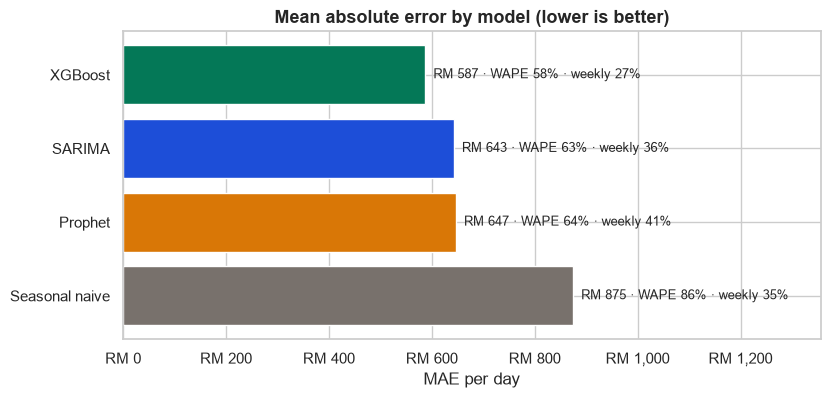

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
ordered = results.sort_values("MAE (RM)", ascending=False)
bars = ax.barh(ordered["model"], ordered["MAE (RM)"], color=[COLORS[n] for n in ordered["model"]])
for bar, (_, row) in zip(bars, ordered.iterrows()):
    ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2,
            f"  RM {row['MAE (RM)']:,.0f} · WAPE {row['WAPE (%)']:.0f}% · weekly {row['weekly total error (%)']:.0f}%", va="center", fontsize=9)
ax.set(title="Mean absolute error by model (lower is better)", xlabel="MAE per day", ylabel="")
ax.set_xlim(0, ordered["MAE (RM)"].max() * 1.55)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"RM {v:,.0f}"))
save(fig, "04_mae_by_model.png")
plt.show()

**Finding:** On daily error, every model beats the seasonal-naive baseline by 26–33%, with XGBoost lowest. Only XGBoost also beats it on weekly totals, which is the number the admin sees. That makes XGBoost the clear choice for the dashboard.

## 5. Best model: retrain on all data and forecast the next 30 days
The model with the lowest MAE is retrained on **all** days (including the test period) and forecasts the next 30 days.

saved 04_next_30_days_forecast.png


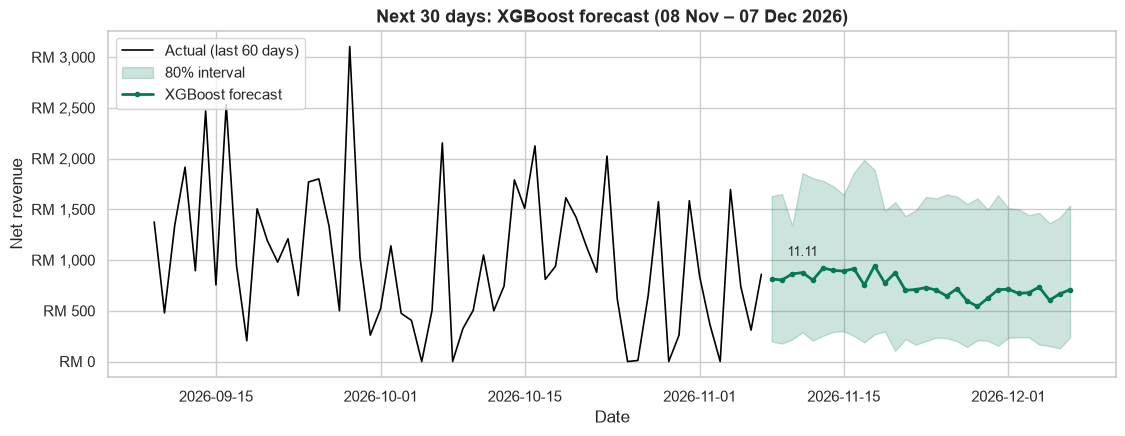

Next 7 days total: RM 5,980 (80% range from backtest weekly errors: RM 3,983 – 8,780) · last 7 days actual RM 4,810 · next 30 days RM 22,588


,day,yhat,lower,upper
2026-11-08 00:00:00,Sun,RM 814,RM 198,"RM 1,629"
2026-11-09 00:00:00,Mon,RM 803,RM 177,"RM 1,652"
2026-11-10 00:00:00,Tue,RM 864,RM 218,"RM 1,337"
2026-11-11 00:00:00,Wed,RM 877,RM 288,"RM 1,857"
2026-11-12 00:00:00,Thu,RM 803,RM 206,"RM 1,808"
2026-11-13 00:00:00,Fri,RM 921,RM 254,"RM 1,781"
2026-11-14 00:00:00,Sat,RM 898,RM 292,"RM 1,727"


In [9]:
best_name = results.loc[0, "model"]
best_model = {m.name: m for m in [SeasonalNaive(), Sarima(best_order, best_seasonal), ProphetModel(), XGBoostModel()]}[best_name]
best_model.fit(y)
future = pd.date_range(y.index.max() + pd.Timedelta(days=1), periods=30, freq="D")
forecast = best_model.predict(future)

recent = y[y.index > y.index.max() - pd.Timedelta(days=60)]
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(recent.index, recent.values, color="black", lw=1.2, label="Actual (last 60 days)")
ax.fill_between(forecast.index, forecast["lower"], forecast["upper"], color=COLORS[best_name], alpha=0.2, label="80% interval")
ax.plot(forecast.index, forecast["yhat"], color=COLORS[best_name], lw=2, marker="o", ms=3, label=f"{best_name} forecast")
for d in forecast.index[calendar_features(forecast.index)["double_day"] == 1]:
    ax.annotate("11.11" if d.month == 11 else f"{d.day}.{d.month}", (d, forecast.loc[d, "yhat"]), textcoords="offset points", xytext=(0, 12), ha="center", fontsize=9)
ax.set(title=f"Next 30 days: {best_name} forecast ({future[0]:%d %b} – {future[-1]:%d %b %Y})", xlabel="Date", ylabel="Net revenue")
rm_axis(ax)
ax.legend(loc="upper left")
save(fig, "04_next_30_days_forecast.png")
plt.show()

# Weekly range: daily intervals can't simply be added up, so use the backtest's weekly errors
# (actual ÷ forecast per week, 10th–90th percentile) for this model.
best_weeks = backtest[backtest["model"] == best_name].groupby("origin")[["actual", "yhat"]].sum()
ratio_low, ratio_high = (best_weeks["actual"] / best_weeks["yhat"]).quantile([0.1, 0.9])
next7 = forecast.iloc[:7].copy()
next7.insert(0, "day", next7.index.day_name().str[:3])
week_total = next7["yhat"].sum()
print(f"Next 7 days total: RM {week_total:,.0f} (80% range from backtest weekly errors: RM {week_total * ratio_low:,.0f} – {week_total * ratio_high:,.0f}) · "
      f"last 7 days actual RM {y.iloc[-7:].sum():,.0f} · next 30 days RM {forecast['yhat'].sum():,.0f}")
next7.style.format({"yhat": "RM {:,.0f}", "lower": "RM {:,.0f}", "upper": "RM {:,.0f}"})

**Finding:** XGBoost forecasts **RM 5,980 for 8–14 Nov 2026**, with an 80% range of about RM 4,000 – 8,800 based on the backtest's weekly errors (actual was 0.67–1.47× the forecast). Last week's actual was RM 4,810. The forecast is flat at about RM 800–920 a day, so it does **not** show the 11.11 spike (see the event check below). The next 30 days total about RM 22,600.

### Event check: 11.11
The test window (9 Aug – 7 Nov 2026) holds 9.9 and 10.10 but no 11.11, so the backtest doesn't measure the biggest sales day.
Here every model is trained on all data and asked for 11.11 2026, next to the real 11.11 of past years.

In [10]:
event_day = pd.Timestamp("2026-11-11")
check = {}
for model in [Sarima(best_order, best_seasonal), ProphetModel(), XGBoostModel()]:
    f = model.fit(y).predict(future[:7])
    check[model.name] = {"11.11 forecast (RM)": f.loc[event_day, "yhat"], "other days in the week (RM)": f.drop(event_day)["yhat"].mean()}
check = pd.DataFrame(check).T
check["lift"] = check["11.11 forecast (RM)"] / check["other days in the week (RM)"]
past = {f"11.11 {yr}": y[f"{yr}-11-11"] / y[pd.Timestamp(f"{yr}-11-11") - pd.Timedelta(days=28):pd.Timestamp(f"{yr}-11-11") - pd.Timedelta(days=1)].mean() for yr in (2024, 2025)}
print("Actual 11.11 lift vs the previous 28 days:", ", ".join(f"{k}: {v:.1f}x (RM {y[k[-4:] + '-11-11']:,.0f})" for k, v in past.items()))
check.style.format({"11.11 forecast (RM)": "RM {:,.0f}", "other days in the week (RM)": "RM {:,.0f}", "lift": "{:.2f}x"})

Actual 11.11 lift vs the previous 28 days: 11.11 2024: 2.4x (RM 1,640), 11.11 2025: 2.8x (RM 2,050)


,11.11 forecast (RM),other days in the week (RM),lift
SARIMA,"RM 1,713","RM 1,134",1.51x
Prophet,"RM 1,669","RM 1,071",1.56x
XGBoost,RM 877,RM 851,1.03x


**Finding:** XGBoost forecasts 11.11 at almost a normal day (about 1.0×). SARIMA and Prophet do give it a lift (about 1.5×, RM 1,669–1,713). The real 11.11 was 2.4× (2024) and 2.8× (2025) the previous 28-day average. With only 8 double days in two years, the trees can't learn a reliable spike. So the chosen model is best on normal weeks, but it **under-forecasts event days**, and 11.11 2026 is in the coming week. The admin should expect more than the forecast on 11.11, and a later version should add an event adjustment (for example, Prophet's or the historical 11.11 lift on top of XGBoost).

saved 04_xgboost_feature_importance.png


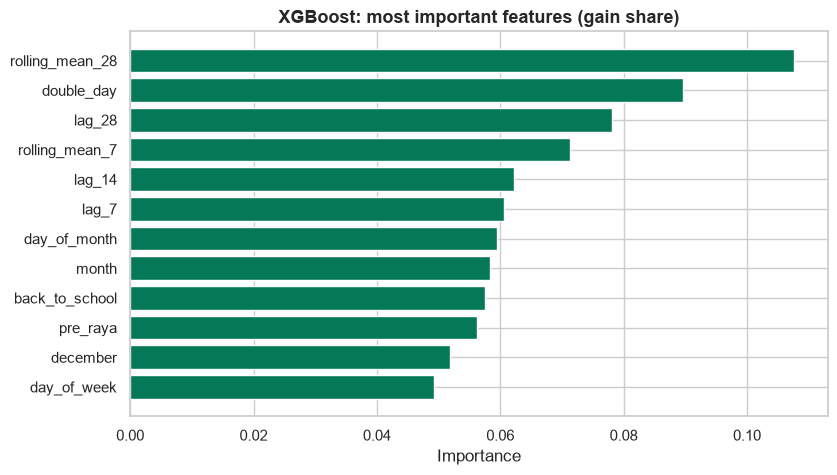

In [11]:
xgb = best_model if best_name == "XGBoost" else XGBoostModel().fit(y)
importance = xgb.feature_importance().head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(importance.index, importance.values, color=COLORS["XGBoost"])
ax.set(title="XGBoost: most important features (gain share)", xlabel="Importance", ylabel="")
save(fig, "04_xgboost_feature_importance.png")
plt.show()

**Finding:** The most important features are the level features (28-day rolling mean, lag 28, 7-day rolling mean, lags 14 and 7). `double_day` ranks second, so the model knows double days matter, but with only 8 examples and median (quantile) training the lift it predicts is small. Day of month and month add some seasonality.

## 6. Save the model
`models/revenue_model_v1.joblib` (v1; notebook 03 writes the current `revenue_model.joblib`) holds the fitted model object (it carries its own history for lags and builds its calendar features from the dates).
Load it with `ml-service/` on `sys.path` (the `forecasting` package must be importable), then call `model.predict(dates)` for dates after `trained_until`.

In [12]:
from importlib.metadata import version

model_path = MODEL_DIR / "revenue_model_v1.joblib"
joblib.dump(best_model, model_path)

best_metrics = results.set_index("model").loc[best_name].drop("MAE vs baseline")
metadata = {
    "model_name": best_name,
    "model_class": f"forecasting.models.{type(best_model).__name__}",
    "target": "daily net revenue (RM): paid orders (status paid/shipped/completed/refunded), dated by paid_at in Malaysia time (UTC+8), total - refunded_amount",
    "trained_from": f"{y.index.min():%Y-%m-%d}",
    "trained_until": f"{best_model.trained_until_:%Y-%m-%d}",
    "training_days": int(len(y)),
    "interval": "80% prediction interval (lower, upper)",
    "features": list(best_model.features),
    "evaluation": {
        "method": f"rolling-origin backtest: last {TEST_DAYS} days, refit every {STEP} days, forecast {STEP} days ahead",
        "test_from": f"{test_start:%Y-%m-%d}", "test_until": f"{y.index.max():%Y-%m-%d}",
        "metrics": {k: round(float(v), 2) for k, v in best_metrics.items()},
        "all_models": results.drop(columns="MAE vs baseline").round(2).to_dict(orient="records"),
    },
    "sarima_order": {"order": list(best_order), "seasonal_order": list(best_seasonal)},
    "created_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "versions": {p: version(p) for p in ["pandas", "numpy", "scikit-learn", "xgboost", "statsmodels", "prophet", "joblib"]},
    "load": "sys.path.insert(0, 'ml-service'); model = joblib.load('ml-service/models/revenue_model_v1.joblib'); model.predict(dates)",
}
(MODEL_DIR / "revenue_model_v1.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")

# Check the saved file gives the same forecast.
reloaded = joblib.load(model_path)
assert np.allclose(reloaded.predict(future)["yhat"], forecast["yhat"])
print(f"saved {model_path.name} ({model_path.stat().st_size / 1024:,.0f} KB) and revenue_model_v1.json · reload check passed")
print(json.dumps({k: metadata[k] for k in ["model_name", "trained_until", "training_days"]}, indent=2))

saved revenue_model_v1.joblib (1,376 KB) and revenue_model_v1.json · reload check passed
{
  "model_name": "XGBoost",
  "trained_until": "2026-11-07",
  "training_days": 737
}


## 7. Summary

- **Chosen model: XGBoost**, with the lowest daily error (MAE RM 587, 33% below the seasonal-naive baseline) and the only model that beats the baseline on weekly totals (27% error, −4% bias). It is retrained on all 737 days and saved as `models/revenue_model.joblib`, trained until 7 Nov 2026.
- **Show weekly totals, not daily numbers.** Every model has a daily WAPE of 58% or more, because single days are mostly noise. Weekly totals are much more reliable.
- **SARIMA and Prophet over-forecast** weekly totals by about 25%, because they extend the early-2026 growth. The AIC grid found no ARMA or seasonal terms worth adding, so SARIMA reduces to trend + calendar.
- **The intervals are too narrow.** The models' 80% intervals covered only 58–65% of actual days. For the dashboard, use the weekly range measured in the backtest (0.67–1.47× the forecast) instead.
- **Event days are the weak spot.** XGBoost does not forecast the 11.11 spike (real lift 2.4–2.8×), while Prophet and SARIMA show part of it. Next step: add an event adjustment on top of XGBoost, and test on a window that includes 11.11 and 12.12.
- **Next 7 days (8–14 Nov 2026):** about RM 5,980 (range about RM 4,000 – 8,800), plus an expected 11.11 boost the model misses.
- **Caveats:** the data is semi-synthetic, the holiday dates are provisional, and the model should be retrained every week, as in the backtest.